# EX 8 – Train a Simple Autoencoder for Dimensionality Reduction and Feature Learning
**Name:** Jeevanantham K  |  **Roll No:** 24BAD047  |  **Date:** 30-Oct-2026

**Aim:** To implement and train a simple autoencoder on MNIST, learn a lower-dimensional (32-D) representation, and evaluate it by reconstructing images and visualizing latent features.

## Pre-Lab Questions

1. **What is an autoencoder?** An unsupervised neural network that learns to compress its input into a compact code and then reconstruct the input from that code.
2. **Roles of encoder and decoder?** The encoder maps the input to a lower-dimensional latent vector; the decoder reconstructs the original input from that latent vector.
3. **What is dimensionality reduction?** Representing data with fewer features while preserving as much useful information as possible (e.g., 784 → 32).
4. **Latent representation / latent space?** The compressed bottleneck vector produced by the encoder; the space of all such vectors is the latent space, capturing the essential features of the data.
5. **Why reconstruction loss?** It measures how close the output is to the input (MSE / binary cross-entropy). Minimising it forces the network to keep the most informative features in the latent code.

## Part A: Dataset Preparation and Preprocessing

In [1]:
# Student details
STUDENT_NAME = "Jeevanantham K"
ROLL_NO      = "24BAD047"
DATE         = "30-Oct-2026"
print(f"Name: {STUDENT_NAME} | Roll No: {ROLL_NO} | Date: {DATE}")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model

np.random.seed(47); tf.random.set_seed(47)
print("TensorFlow version:", tf.__version__)

Name: Jeevanantham K | Roll No: 24BAD047 | Date: 30-Oct-2026
TensorFlow version: 2.21.0


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[24BAD047] Training images: (60000, 28, 28)
[24BAD047] Testing images : (10000, 28, 28)
[24BAD047] Image dimension: (28, 28) | Pixel range: 0 - 255


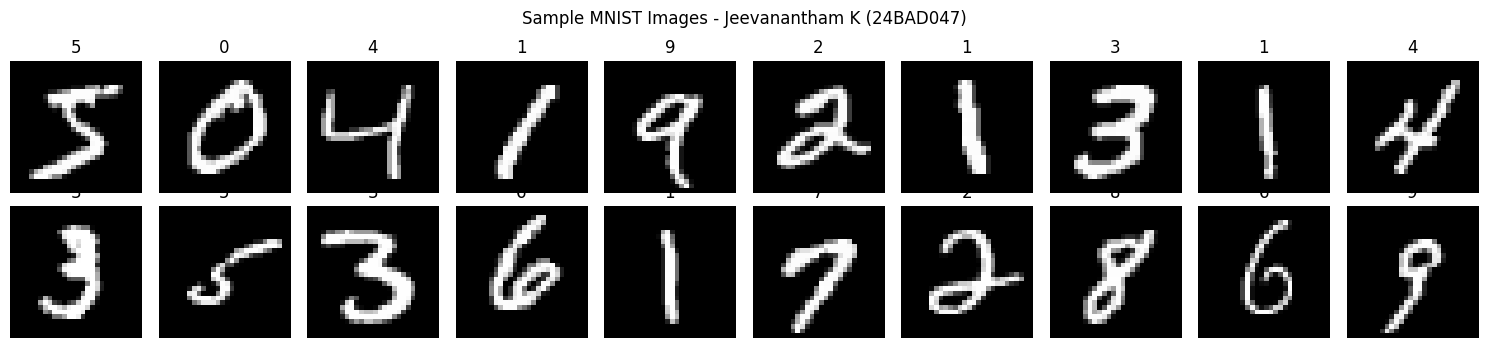

In [2]:
# Load MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print(f"[{ROLL_NO}] Training images:", x_train.shape)
print(f"[{ROLL_NO}] Testing images :", x_test.shape)
print(f"[{ROLL_NO}] Image dimension:", x_train.shape[1:], "| Pixel range:", x_train.min(), "-", x_train.max())

# Display sample images
fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray"); ax.set_title(str(y_train[i])); ax.axis("off")
plt.suptitle(f"Sample MNIST Images - {STUDENT_NAME} ({ROLL_NO})")
plt.tight_layout(); plt.show()

In [3]:
# Normalize to [0,1] and flatten 28x28 -> 784
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32")  / 255.0
x_train_flat = x_train.reshape(len(x_train), -1)
x_test_flat  = x_test.reshape(len(x_test), -1)

print(f"[{ROLL_NO}] Flattened train:", x_train_flat.shape)
print(f"[{ROLL_NO}] Flattened test :", x_test_flat.shape)
print(f"[{ROLL_NO}] Pixel range after normalization: {x_train_flat.min()} - {x_train_flat.max()}")
# Autoencoder: input = target (x_train_flat, x_train_flat)

[24BAD047] Flattened train: (60000, 784)
[24BAD047] Flattened test : (10000, 784)
[24BAD047] Pixel range after normalization: 0.0 - 1.0


## Part B: Implementing the Encoder and Decoder

In [4]:
INPUT_DIM, LATENT_DIM = 784, 32

# Encoder
enc_in = keras.Input(shape=(INPUT_DIM,), name="encoder_input")
x = layers.Dense(128, activation="relu")(enc_in)
x = layers.Dense(64,  activation="relu")(x)
latent = layers.Dense(LATENT_DIM, activation="relu", name="latent_vector")(x)
encoder = Model(enc_in, latent, name=f"encoder_{ROLL_NO}")

# Decoder
dec_in = keras.Input(shape=(LATENT_DIM,), name="decoder_input")
y = layers.Dense(64,  activation="relu")(dec_in)
y = layers.Dense(128, activation="relu")(y)
dec_out = layers.Dense(INPUT_DIM, activation="sigmoid", name="reconstruction")(y)
decoder = Model(dec_in, dec_out, name=f"decoder_{ROLL_NO}")

# Autoencoder = decoder(encoder(input))
ae_in = keras.Input(shape=(INPUT_DIM,))
autoencoder = Model(ae_in, decoder(encoder(ae_in)), name=f"autoencoder_{ROLL_NO}")

print(f"--- {STUDENT_NAME} ({ROLL_NO}) ---")
encoder.summary()
decoder.summary()
autoencoder.summary()

--- Jeevanantham K (24BAD047) ---


Model: "encoder_24BAD047"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

...

Model: "autoencoder_24BAD047"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_24BAD047 (Functional)   │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_24BAD047 (Functional)   │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

## Part C: Compiling and Training the Autoencoder

In [5]:
autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                    loss="binary_crossentropy",
                    metrics=["mse"])

history = autoencoder.fit(x_train_flat, x_train_flat,
                          epochs=10, batch_size=256, shuffle=True,
                          validation_data=(x_test_flat, x_test_flat), verbose=1)
print(f"[{ROLL_NO}] Training complete.")

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2397 - mse: 0.0590 - val_loss: 0.1615 - val_mse: 0.0332
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1482 - mse: 0.0285 - val_loss: 0.1352 - val_mse: 0.0241
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1302 - mse: 0.0224 - val_loss: 0.1228 - val_mse: 0.0200
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1204 - mse: 0.0192 - val_loss: 0.1149 - val_mse: 0.0174
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1134 - mse: 0.0169 - val_loss: 0.1094 - val_mse: 0.0156
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1093 - mse: 0.0155 - val_loss: 0.1064 - val_mse: 0.0146
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.1067 - mse: 0.0146 - val_loss: 0.1039 - val_mse: 0.0138
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1044 - mse: 0.0139 - val_loss: 0.1020 - val_mse: 0.0132
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - l

Epoch  1 | train loss = 0.2397 | val loss = 0.1615
Epoch  2 | train loss = 0.1482 | val loss = 0.1352
Epoch  3 | train loss = 0.1302 | val loss = 0.1228
Epoch  4 | train loss = 0.1204 | val loss = 0.1149
Epoch  5 | train loss = 0.1134 | val loss = 0.1094
Epoch  6 | train loss = 0.1093 | val loss = 0.1064
Epoch  7 | train loss = 0.1067 | val loss = 0.1039
Epoch  8 | train loss = 0.1044 | val loss = 0.1020
Epoch  9 | train loss = 0.1025 | val loss = 0.1003
Epoch 10 | train loss = 0.1009 | val loss = 0.0989


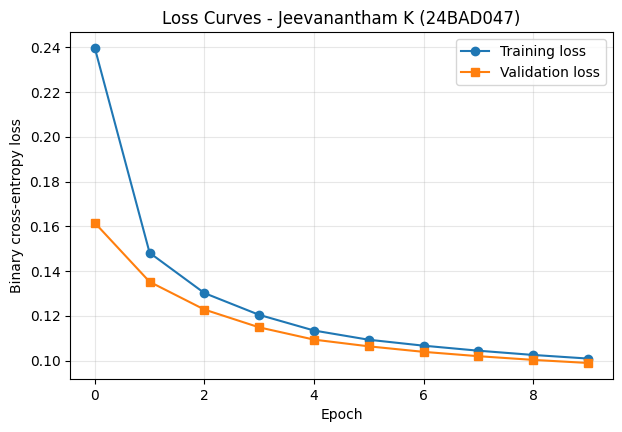

[24BAD047] Test BCE loss: 0.0989 | Test MSE: 0.01220


In [6]:
# Loss values per epoch
for e,(tl,vl) in enumerate(zip(history.history["loss"], history.history["val_loss"]),1):
    print(f"Epoch {e:2d} | train loss = {tl:.4f} | val loss = {vl:.4f}")

plt.figure(figsize=(7,4.5))
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="s", label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy loss")
plt.title(f"Loss Curves - {STUDENT_NAME} ({ROLL_NO})")
plt.legend(); plt.grid(alpha=.3); plt.show()

test_loss, test_mse = autoencoder.evaluate(x_test_flat, x_test_flat, verbose=0)
print(f"[{ROLL_NO}] Test BCE loss: {test_loss:.4f} | Test MSE: {test_mse:.5f}")

## Part D: Dimensionality Reduction, Feature Learning and Reconstruction

In [7]:
latent_test = encoder.predict(x_test_flat, verbose=0)
reconstructed = decoder.predict(latent_test, verbose=0)

print(f"[{ROLL_NO}] Original input dimension : {x_test_flat.shape[1]}")
print(f"[{ROLL_NO}] Latent dimension         : {latent_test.shape[1]}")
print(f"[{ROLL_NO}] Compression ratio        : {x_test_flat.shape[1]/latent_test.shape[1]:.1f}x")
print(f"[{ROLL_NO}] Reconstructed shape      : {reconstructed.shape}")
print("Sample latent vector (first image):\n", np.round(latent_test[0], 3))

[24BAD047] Original input dimension : 784
[24BAD047] Latent dimension         : 32
[24BAD047] Compression ratio        : 24.5x
[24BAD047] Reconstructed shape      : (10000, 784)
Sample latent vector (first image):
 [ 0.     3.963 10.533  7.218  0.     0.     0.    11.229  6.338 19.313
 13.3    5.369  9.3   14.398  7.996  0.     0.     9.83   0.     7.986
 13.867  5.249  5.818 18.696  8.253  6.628  9.974 16.092 11.906  8.608
  3.545  9.752]


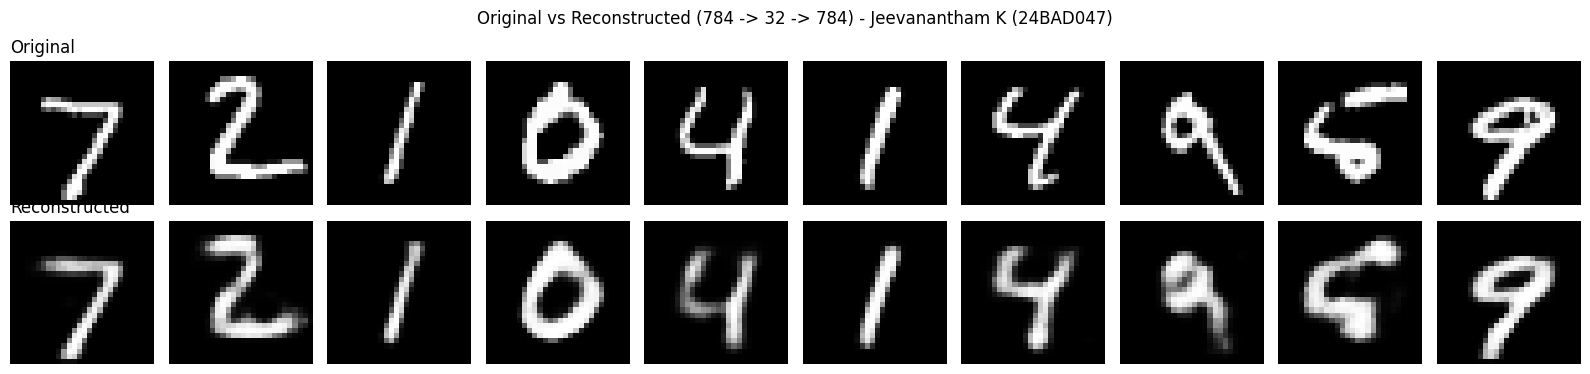

[24BAD047] Mean per-image MSE: 0.01220 (best 0.00071, worst 0.05344)


In [8]:
# Original vs reconstructed
n = 10
fig, axes = plt.subplots(2, n, figsize=(16, 3.8))
for i in range(n):
    axes[0,i].imshow(x_test_flat[i].reshape(28,28), cmap="gray"); axes[0,i].axis("off")
    axes[1,i].imshow(reconstructed[i].reshape(28,28), cmap="gray"); axes[1,i].axis("off")
axes[0,0].set_title("Original", loc="left"); axes[1,0].set_title("Reconstructed", loc="left")
plt.suptitle(f"Original vs Reconstructed (784 -> 32 -> 784) - {STUDENT_NAME} ({ROLL_NO})")
plt.tight_layout(); plt.show()

per_img_mse = np.mean((x_test_flat - reconstructed)**2, axis=1)
print(f"[{ROLL_NO}] Mean per-image MSE: {per_img_mse.mean():.5f} (best {per_img_mse.min():.5f}, worst {per_img_mse.max():.5f})")

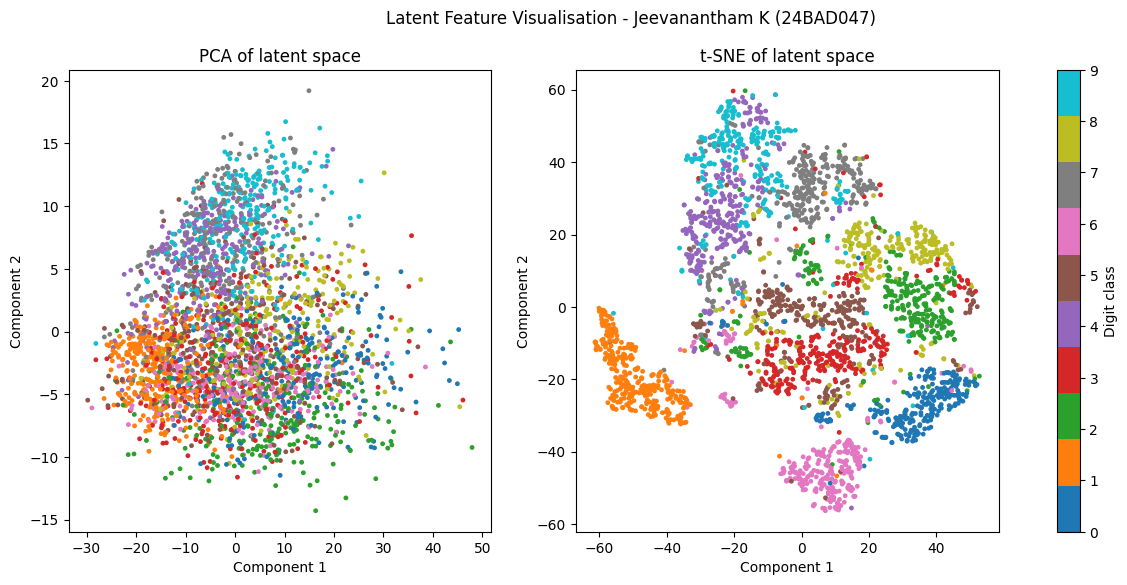

In [9]:
# Latent features visualised in 2-D using PCA and t-SNE
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

N = 3000
lat, lab = latent_test[:N], y_test[:N]

pca2 = PCA(n_components=2).fit_transform(lat)
tsne2 = TSNE(n_components=2, perplexity=30, random_state=47, init="pca").fit_transform(lat)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, data, t in zip(axes, [pca2, tsne2], ["PCA of latent space", "t-SNE of latent space"]):
    sc = ax.scatter(data[:,0], data[:,1], c=lab, cmap="tab10", s=6)
    ax.set_title(t); ax.set_xlabel("Component 1"); ax.set_ylabel("Component 2")
fig.colorbar(sc, ax=axes, label="Digit class")
plt.suptitle(f"Latent Feature Visualisation - {STUDENT_NAME} ({ROLL_NO})")
plt.show()

In [10]:
# Save models and reconstructed images
autoencoder.save(f"autoencoder_{ROLL_NO}.keras")
encoder.save(f"encoder_{ROLL_NO}.keras")
decoder.save(f"decoder_{ROLL_NO}.keras")
np.save(f"reconstructed_{ROLL_NO}.npy", reconstructed[:100])
print(f"[{ROLL_NO}] Saved models and reconstructed images.")

[24BAD047] Saved models and reconstructed images.


### Observation
- The 784-pixel images were compressed into 32 values (24.5x reduction) and reconstructed well; digit identity and overall shape are preserved.
- Fine details (thin strokes, sharp edges, stroke thickness) are slightly blurred, showing some information is lost in compression.
- Training and validation loss decreased together with a small gap, indicating no significant overfitting.
- The PCA/t-SNE plots show digits forming clusters, so the latent features are meaningful even though no labels were used for training.

## Post-Lab Questions

1. **Main purpose of an autoencoder?** To learn a compact representation of data (dimensionality reduction / feature learning) by reconstructing its own input.
2. **Encoder vs decoder?** The encoder compresses the input into the latent vector (784 → 32); the decoder expands the latent vector back to the original size (32 → 784).
3. **Latent representation?** The low-dimensional bottleneck vector holding the most important features of the input.
4. **How does it perform dimensionality reduction?** The bottleneck layer has far fewer units than the input, so the network must keep only the most informative features; the encoder output is the reduced representation.
5. **Why input images as targets?** Autoencoders are self-supervised: the goal is to reproduce the input, so no separate labels are needed and the input itself is the ground truth.
6. **What does reconstruction loss measure?** The difference between the original input and the reconstructed output (e.g., MSE or binary cross-entropy); lower loss means better reconstruction.
7. **If the latent dimension is too small?** Too much information is lost (underfitting), giving blurry or inaccurate reconstructions and poor features.
8. **Real-world application:** Image denoising, anomaly/fraud detection, image compression, or feature extraction for downstream models.